# 05. Merge Dữ Liệu Đơn Hàng Với Trả Hàng & Quản Lý Khu Vực


In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Tự động đọc dữ liệu từ thư mục data/raw
if os.path.exists("train.csv"):
  data_dir = "."
elif os.path.exists("../data/raw/train.csv"):
  data_dir = "../data/raw"
elif os.path.exists("data/raw/train.csv"):
  data_dir = "data/raw"
else:
  data_dir = "../../data/raw"

df_orders = pd.read_csv(os.path.join(data_dir, "train.csv"))
df_returns = pd.read_csv(os.path.join(data_dir, "returns.csv"))

manager_path = os.path.join(data_dir, "region_managers.csv")
if not os.path.exists(manager_path):
  manager_path = os.path.join(data_dir, "region_managers")
df_managers = pd.read_csv(manager_path)

# 2. Làm sạch dữ liệu và xử lý thời gian
df_orders["Order Date"] = pd.to_datetime(
    df_orders["Order Date"], dayfirst=True, errors="coerce"
)
df_orders["Ship Date"] = pd.to_datetime(
    df_orders["Ship Date"], dayfirst=True, errors="coerce"
)
df_orders = df_orders.dropna(subset=["Postal Code"]).copy()

# 3. Thực hiện Merge 3 bảng dữ liệu
# Bảng 1: Orders + Returns (Khóa chung: 'Order ID')
df_merged = pd.merge(df_orders, df_returns, on="Order ID", how="left")
df_merged["Returned"] = df_merged["Returned"].fillna("No")
df_merged["Return Reason"] = df_merged["Return Reason"].fillna("None")

# Bảng 2: Results + Region Managers (Khóa chung: 'Region')
df_merged = pd.merge(df_merged, df_managers, on="Region", how="left")

# 4. In kết quả thống kê chi tiết ra màn hình
print(
    f"=== THỐNG KÊ KẾT QUẢ MERGE DỮ LIỆU TRÊN TẬP ĐÃ LÀM SẠCH ({len(df_merged)}"
    " DÒNG) ==="
)
returned_count = (df_merged["Returned"] == "Yes").sum()
print(
    f"- Số lượng đơn bị trả lại (Returned): {returned_count}/{len(df_merged)}"
    f" dòng ({returned_count/len(df_merged)*100:.2f}%)"
)
print(
    f"- Số khu vực có Quản lý (Regional Manager):"
    f" {df_merged['Regional Manager'].nunique()} khu vực\n"
)

# Thống kê Doanh thu thực tế vs Target theo khu vực
region_perf = (
    df_merged.groupby(["Region", "Regional Manager", "Target Sales 2017"])["Sales"]
    .sum()
    .reset_index()
)
region_perf.rename(columns={"Sales": "Actual Sales"}, inplace=True)
region_perf["Achievement (%)"] = (
    region_perf["Actual Sales"] / region_perf["Target Sales 2017"] * 100
)

print("=== SO SÁNH DOANH THU THỰC TẾ VÀ TARGET THEO KHU VỰC ===")
print(region_perf.round(2))

=== THỐNG KÊ KẾT QUẢ MERGE DỮ LIỆU TRÊN TẬP ĐÃ LÀM SẠCH (9789 DÒNG) ===
- Số lượng đơn bị trả lại (Returned): 818/9789 dòng (8.36%)
- Số khu vực có Quản lý (Regional Manager): 4 khu vực

=== SO SÁNH DOANH THU THỰC TẾ VÀ TARGET THEO KHU VỰC ===
    Region   Regional Manager  Target Sales 2017  Actual Sales  \
0  Central     Kelly Williams             500000     492646.91   
1     East        Chuck Magee             680000     660589.36   
2    South  Cassandra Brandow             400000     389151.46   
3     West      Anna Andreadi             750000     710219.68   

   Achievement (%)  
0            98.53  
1            97.15  
2            97.29  
3            94.70  


C:\Users\minhv\AppData\Local\Temp\ipykernel_5220\46621262.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


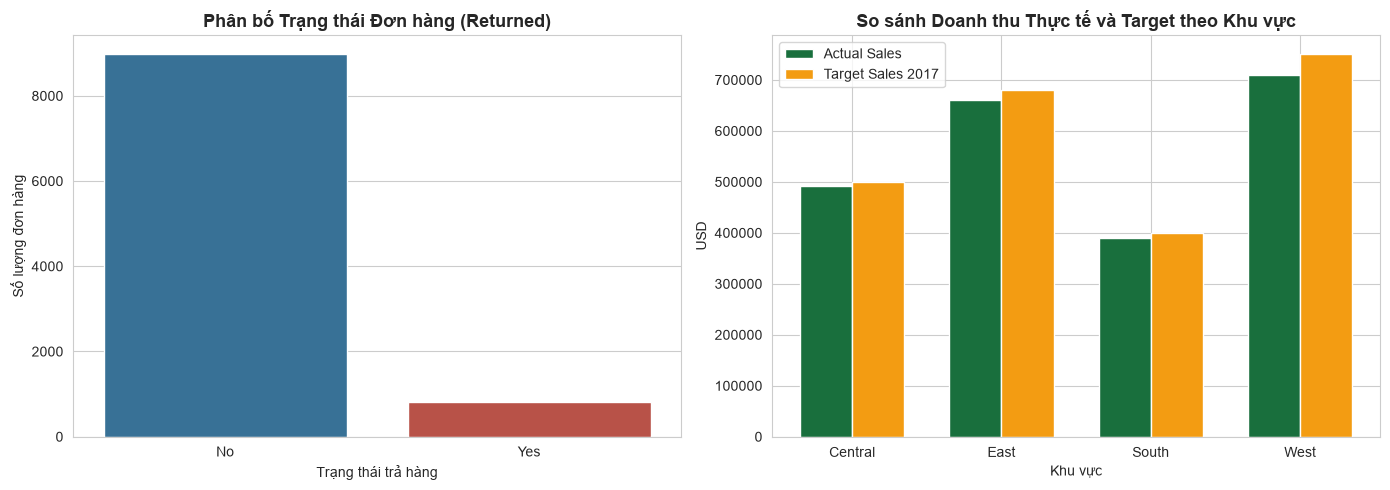

In [3]:
# 5. Vẽ biểu đồ trực quan hóa kết quả
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Tỷ lệ trả hàng
sns.countplot(
    x="Returned", data=df_merged, ax=axes[0], palette=["#2874A6", "#CB4335"]
)
axes[0].set_title(
    "Phân bố Trạng thái Đơn hàng (Returned)", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Trạng thái trả hàng")
axes[0].set_ylabel("Số lượng đơn hàng")

# Biểu đồ 2: So sánh Actual Sales và Target Sales theo khu vực
x_indexes = np.arange(len(region_perf))
width = 0.35
axes[1].bar(
    x_indexes - width / 2,
    region_perf["Actual Sales"],
    width=width,
    label="Actual Sales",
    color="#196F3D",
)
axes[1].bar(
    x_indexes + width / 2,
    region_perf["Target Sales 2017"],
    width=width,
    label="Target Sales 2017",
    color="#F39C12",
)
axes[1].set_title(
    "So sánh Doanh thu Thực tế và Target theo Khu vực",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xticks(x_indexes)
axes[1].set_xticklabels(region_perf["Region"])
axes[1].set_xlabel("Khu vực")
axes[1].set_ylabel("USD")
axes[1].legend()

plt.tight_layout()
chart_filename = "15_region_performance_analysis.png"
plt.savefig(chart_filename, dpi=150, bbox_inches="tight")
plt.show()

# 6. Lưu file dữ liệu đã gộp hoàn chỉnh
output_dir = "../data/processed" if os.path.exists("../data") else "data/processed"
if not os.path.exists(output_dir):
  os.makedirs(output_dir, exist_ok=True)

output_csv = os.path.join(output_dir, "train_merged.csv")
df_merged.to_csv(output_csv, index=False)

try:
  from google.colab import files

  files.download(chart_filename)
  files.download(output_csv)
  print("\n=> Đã tự động tải ảnh biểu đồ và file CSV sạch về máy tính của bạn!")
except:
  pass